In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, RandomizedSearchCV, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBRegressor

## 1. Load Data

In [2]:
DATA_DIR = "F:/ai/Project github/house-prices" # train.csv and test.csv go here
train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
test_df = pd.read_csv(f"{DATA_DIR}/test.csv")
print(train_df.shape, test_df.shape)
train_df.head()

(1460, 81) (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
missing = train_df.isna().sum().sort_values(ascending=False)
missing[missing > 0]

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageYrBlt       81
GarageCond        81
GarageType        81
GarageFinish      81
GarageQual        81
BsmtFinType2      38
BsmtExposure      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

## 2. Target distribution

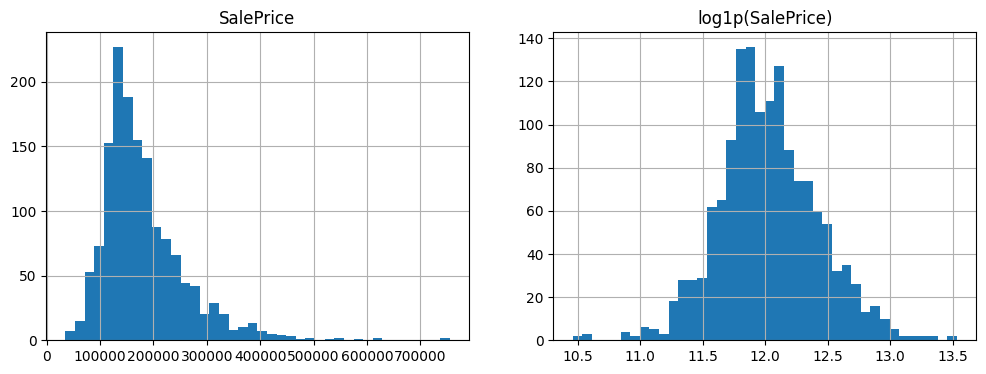

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
train_df['SalePrice'].hist(bins=40, ax=axes[0])
axes[0].set_title('SalePrice')
np.log1p(train_df['SalePrice']).hist(bins=40, ax=axes[1])
axes[1].set_title('log1p(SalePrice)')
plt.show()

## 3. Remove extreme outliers

Removing 2 rows


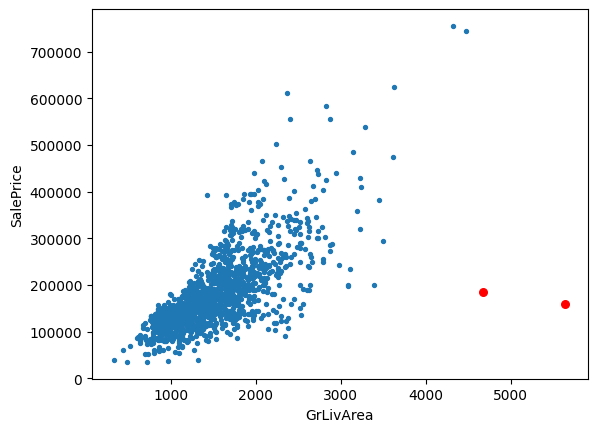

In [5]:
outliers = train_df[(train_df['GrLivArea'] > 4000) & (train_df['SalePrice'] < 300000)]
print("Removing", len(outliers), "rows")

plt.scatter(train_df['GrLivArea'], train_df['SalePrice'], s=8)
plt.scatter(outliers['GrLivArea'], outliers['SalePrice'], color='red', s=30)
plt.xlabel("GrLivArea")
plt.ylabel("SalePrice")
plt.show()

train_df = train_df.drop(index=outliers.index).reset_index(drop=True)

## 4. Prepare features

In [6]:
test_ids = test_df["Id"]
y = np.log1p(train_df["SalePrice"])
X = train_df.drop(columns=["Id", "SalePrice"])
X_test = test_df.drop(columns=["Id"])

for d in (X, X_test):
    d["MSSubClass"] = d["MSSubClass"].astype(str)

num_cols = X.select_dtypes(exclude="object").columns.tolist()
cat_cols = X.select_dtypes(include="object").columns.tolist()
print(len(num_cols), "numeric,", len(cat_cols), "categorical features")

35 numeric, 44 categorical features


In [7]:
def make_preprocessor(scale=False):
    """Impute + encode. For categoricals, NaN means 'feature not present' (e.g. no alley, no garage)."""
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scaler", StandardScaler()))

    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="None")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_cols),
        ("cat", cat_pipe, cat_cols),
    ])

## 5. Train / validation split and baseline models

In [8]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

results = []

def evaluate(name, model):
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    price_true, price_pred = np.expm1(y_val), np.expm1(pred)
    row = {
        "model": name,
        "RMSLE (Kaggle metric)": np.sqrt(mean_squared_error(y_val, pred)),
        "MAE ($)": mean_absolute_error(price_true, price_pred),
        "RMSE ($)": np.sqrt(mean_squared_error(price_true, price_pred)),
        "R2 (log scale)": r2_score(y_val, pred),
    }
    results.append(row)
    return model

ridge = evaluate("Ridge", Pipeline([
    ("prep", make_preprocessor(scale=True)),
    ("model", Ridge(alpha=10)),
]))

rf = evaluate("RandomForest", Pipeline([
    ("prep", make_preprocessor()),
    ("model", RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=42)),
]))

xgb = evaluate("XGBoost (default)", Pipeline([
    ("prep", make_preprocessor()),
    ("model", XGBRegressor(objective="reg:squarederror", random_state=42)),
]))

pd.DataFrame(results).set_index("model").round(4)

,RMSLE (Kaggle metric),MAE ($),RMSE ($),R2 (log scale)
model,,,,
Ridge,0.1227,14305.3832,20007.4396,0.9107
RandomForest,0.1440,16519.1826,24207.4587,0.8770
XGBoost (default),0.1425,17147.4789,24951.2442,0.8795


## 6. Cross-validation (RMSLE, lower is better)

In [9]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
for name, model in [("Ridge", ridge), ("RandomForest", rf), ("XGBoost (default)", xgb)]:
    scores = -cross_val_score(clone(model), X_train, y_train, cv=kf,
                              scoring="neg_root_mean_squared_error", n_jobs=-1)
    print(f"{name:20s} {scores.mean():.4f} +/- {scores.std():.4f}")

Ridge                0.1118 +/- 0.0100
RandomForest         0.1389 +/- 0.0108
XGBoost (default)    0.1413 +/- 0.0075


## 7. Tune XGBoost

In [10]:
xgb_pipe = Pipeline([
    ('prep', make_preprocessor()), 
    ('model', XGBRegressor(objective='reg:squarederror', random_state=42))
])

param_distributions = {
    "model__n_estimators": [100, 200, 300, 500, 800],
    "model__max_depth": [3, 4, 5, 6],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.5, 0.7, 0.8, 1.0],
    "model__min_child_weight": [1, 3, 5],
    "model__gamma": [0, 0.1, 0.3],
    "model__reg_lambda": [0.5, 1, 3, 10],
}

random_search = RandomizedSearchCV(
    xgb_pipe, param_distributions, n_iter=30, cv=kf, 
    scoring="neg_root_mean_squared_error", n_jobs=-1, verbose=1, random_state=42
)
random_search.fit(X_train, y_train)

print("Best params:", random_search.best_params_)
print(f"Best CV RMSLE: {-random_search.best_score_:.4f}")

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best params: {'model__subsample': 0.8, 'model__reg_lambda': 0.5, 'model__n_estimators': 300, 'model__min_child_weight': 1, 'model__max_depth': 5, 'model__learning_rate': 0.05, 'model__gamma': 0, 'model__colsample_bytree': 0.5}
Best CV RMSLE: 0.1205


In [11]:
tuned = evaluate("XGBoost (tuned)", random_search.best_estimator_)
pd.DataFrame(results).set_index("model").round(4)

,RMSLE (Kaggle metric),MAE ($),RMSE ($),R2 (log scale)
model,,,,
Ridge,0.1227,14305.3832,20007.4396,0.9107
RandomForest,0.1440,16519.1826,24207.4587,0.8770
XGBoost (default),0.1425,17147.4789,24951.2442,0.8795
XGBoost (tuned),0.1223,14608.8130,19814.0009,0.9113


## 8. Feature importance

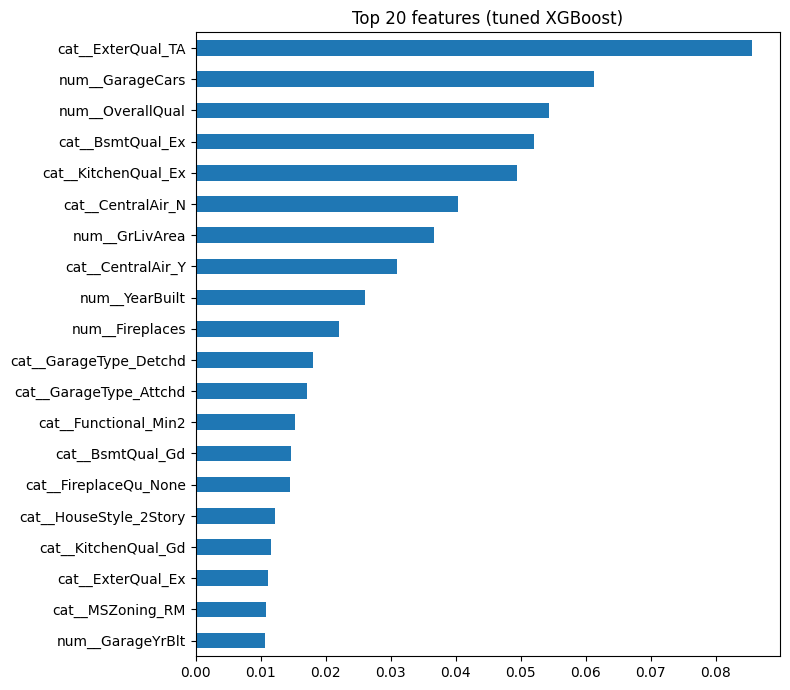

In [12]:
names = tuned.named_steps['prep'].get_feature_names_out()
importances = pd.Series(tuned.named_steps['model'].feature_importances_, index=names)
importances.sort_values().tail(20).plot.barh(figsize=(8, 7), title='Top 20 features (tuned XGBoost)')
plt.tight_layout()
plt.show()

## 9. Final model and submission

Refit the tuned pipeline on **all** training data, predict, and convert back from log prices.

In [13]:
final_model = clone(random_search.best_estimator_)
final_model.fit(X, y)

test_pred = np.expm1(final_model.predict(X_test))

submission = pd.DataFrame({"Id": test_ids, "SalePrice": test_pred})
assert len(submission) == len(test_df) and submission["SalePrice"].notna().all()
submission.to_csv("submission.csv", index=False)
submission.head()

,Id,SalePrice
0,1461,129115.921875
1,1462,157142.750000
2,1463,187591.781250
3,1464,189467.406250
4,1465,186683.015625
